# Distributions: Examples and Simulations

This notebook demonstrates common probability distributions with NumPy and Matplotlib. A fixed seed makes the examples reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
print('NumPy version:', np.__version__)


NumPy version: 2.3.5


## 1. Bernoulli and binomial distributions

A Bernoulli trial is a single success/failure experiment. A binomial random variable counts successes across a fixed number of independent trials.

In [2]:
p = 0.3
bernoulli = rng.binomial(n=1, p=p, size=1000)
binomial = rng.binomial(n=10, p=p, size=1000)
print('Bernoulli observed success rate:', round(bernoulli.mean(), 3))
print('Binomial sample mean:', round(binomial.mean(), 3))
print('Binomial theoretical mean:', 10 * p)
print('Binomial theoretical variance:', 10 * p * (1 - p))


Bernoulli observed success rate: 0.304
Binomial sample mean: 3.072
Binomial theoretical mean: 3.0
Binomial theoretical variance: 2.0999999999999996


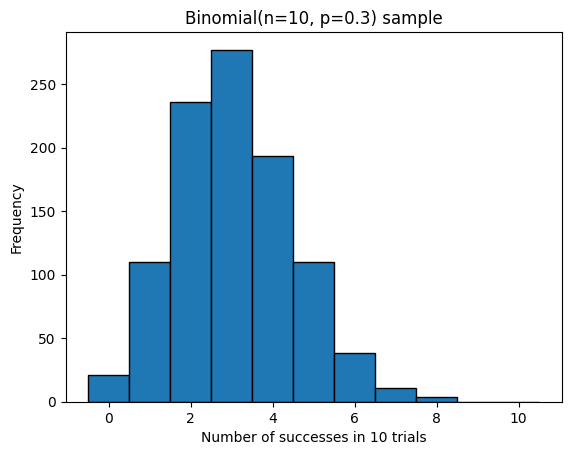

In [3]:
plt.hist(binomial, bins=np.arange(-0.5, 11.5, 1), edgecolor='black')
plt.xlabel('Number of successes in 10 trials')
plt.ylabel('Frequency')
plt.title('Binomial(n=10, p=0.3) sample')
plt.show()


## 2. Geometric distribution

NumPy's geometric sampler returns the trial number of the first success, so values start at 1.

In [4]:
p = 0.2
geometric = rng.geometric(p=p, size=1000)
print('Sample mean:', round(geometric.mean(), 3))
print('Theoretical mean:', 1 / p)
print('Smallest simulated value:', geometric.min())


Sample mean: 4.906
Theoretical mean: 5.0
Smallest simulated value: 1


## 3. Poisson distribution

A Poisson variable counts events in a fixed interval for a plausible constant-rate process.

In [5]:
lam = 4
poisson = rng.poisson(lam=lam, size=2000)
print('Sample mean:', round(poisson.mean(), 3))
print('Sample variance:', round(poisson.var(), 3))
print('Theoretical mean and variance:', lam)


Sample mean: 3.968
Sample variance: 4.114
Theoretical mean and variance: 4


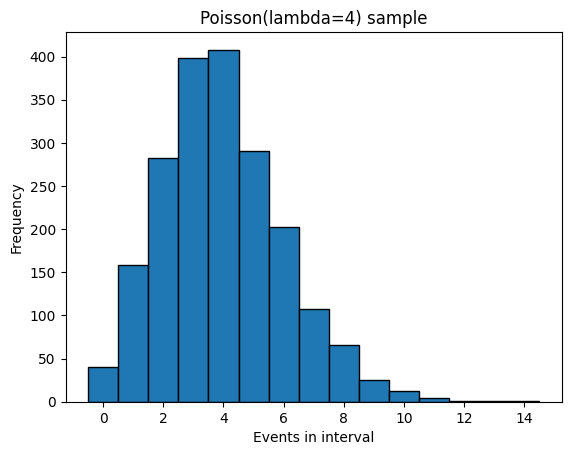

In [6]:
plt.hist(poisson, bins=np.arange(poisson.min() - 0.5, poisson.max() + 1.5, 1), edgecolor='black')
plt.xlabel('Events in interval')
plt.ylabel('Frequency')
plt.title('Poisson(lambda=4) sample')
plt.show()


## 4. Uniform and normal distributions

In [7]:
uniform = rng.uniform(low=2, high=8, size=2000)
normal = rng.normal(loc=50, scale=10, size=2000)
print('Uniform sample mean (theoretical 5):', round(uniform.mean(), 3))
print('Normal sample mean (theoretical 50):', round(normal.mean(), 3))
print('Normal sample standard deviation (theoretical 10):', round(normal.std(), 3))


Uniform sample mean (theoretical 5): 5.036
Normal sample mean (theoretical 50): 50.048
Normal sample standard deviation (theoretical 10): 9.916


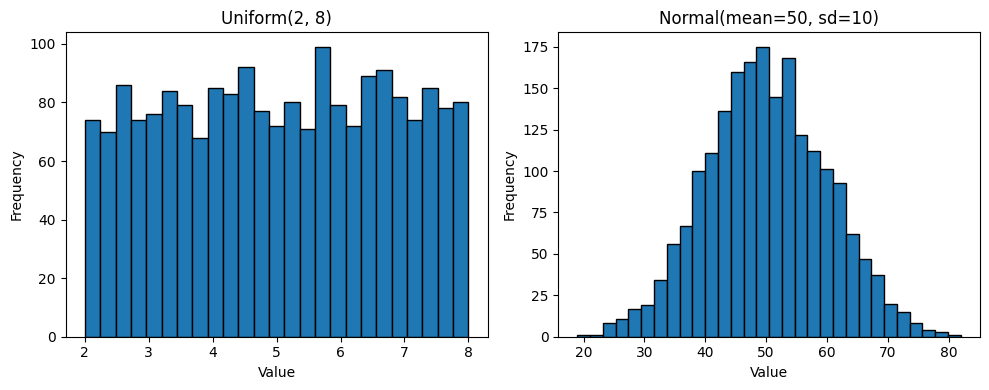

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(uniform, bins=25, edgecolor='black')
axes[0].set_title('Uniform(2, 8)')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Frequency')
axes[1].hist(normal, bins=30, edgecolor='black')
axes[1].set_title('Normal(mean=50, sd=10)')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()


## 5. Exponential waiting times

NumPy uses `scale`, the mean waiting time, which equals `1 / rate`.

In [9]:
rate = 0.5
scale = 1 / rate
waiting_times = rng.exponential(scale=scale, size=2000)
print('Sample mean:', round(waiting_times.mean(), 3))
print('Theoretical mean (scale):', scale)
print('Sample minimum is non-negative:', bool((waiting_times >= 0).all()))


Sample mean: 2.008
Theoretical mean (scale): 2.0
Sample minimum is non-negative: True


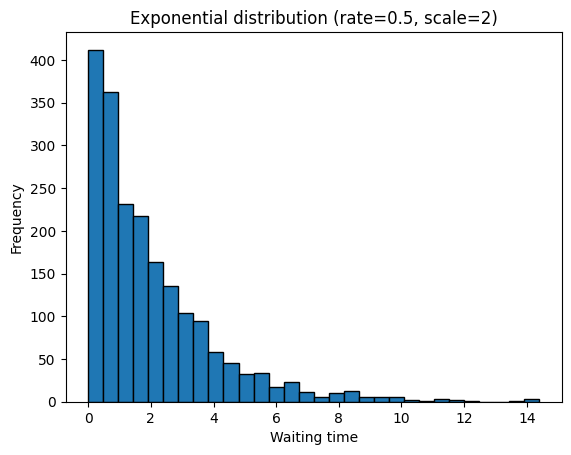

In [10]:
plt.hist(waiting_times, bins=30, edgecolor='black')
plt.xlabel('Waiting time')
plt.ylabel('Frequency')
plt.title('Exponential distribution (rate=0.5, scale=2)')
plt.show()


## 6. Empirical CDF

An empirical CDF gives the fraction of observations at or below each value.

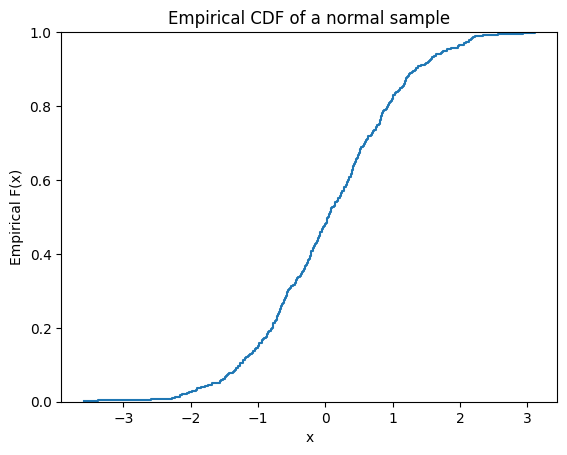

In [11]:
sample = rng.normal(loc=0, scale=1, size=500)
x_sorted = np.sort(sample)
y_ecdf = np.arange(1, len(x_sorted) + 1) / len(x_sorted)
plt.step(x_sorted, y_ecdf, where='post')
plt.xlabel('x')
plt.ylabel('Empirical F(x)')
plt.title('Empirical CDF of a normal sample')
plt.ylim(0, 1)
plt.show()


## 7. Compare theoretical and simulated moments

Finite samples vary, but simulated moments should generally be near theoretical moments when the sample size is sufficiently large.

In [12]:
n, p = 20, 0.4
x = rng.binomial(n=n, p=p, size=10000)
print({'theoretical_mean': n*p, 'sample_mean': float(x.mean()),
       'theoretical_variance': n*p*(1-p), 'sample_variance': float(x.var())})


{'theoretical_mean': 8.0, 'sample_mean': 8.0178, 'theoretical_variance': 4.8, 'sample_variance': 4.81188316}


## Key takeaways

- Discrete distributions model counts or categories; continuous distributions model measurements.
- The distribution's assumptions matter as much as its formula.
- Simulated samples will not match theoretical values exactly.
- A histogram is a useful diagnostic, but it does not prove a distributional model is correct.